# Análisis exploratorio de interacciones

**Equipo:** Grupo 18 (eight nine)  
**Integrantes:** Jorge Cartagena y Santiago Valenzuela  
**Uso de IA:** registro y enlaces en [`USO_IA.md`](../USO_IA.md).

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

PROJECT_ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "tarea_01" / "dataset").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from tarea_01.report_eda import (
    build_eda_artifacts, plot_activity, plot_ratings_time,
    save_figure, top_recipes,
)


In [2]:
dataset_path = PROJECT_ROOT / "tarea_01" / "dataset"
assets_path = PROJECT_ROOT / "tarea_01" / "informe_assets"
df = pd.read_csv(dataset_path / "train.csv")
validation = pd.read_csv(dataset_path / "validation.csv")
df["date"] = pd.to_datetime(df["date"])
validation["date"] = pd.to_datetime(validation["date"])
summary = build_eda_artifacts(dataset_path, assets_path)
display(pd.DataFrame(summary["splits"]))
display(pd.Series(summary["cross_split"], name="Auditoría del split"))


,split,interactions,unique_pairs,users,recipes,density_own_universe,density_train_universe,mean_rating,rating_4_5_fraction,rating_zero_fraction,missing_cells,duplicate_rows,duplicate_pairs,invalid_dates,invalid_ratings,date_min,date_max
0,train,157108,157108,4594,7047,0.004853,0.004853,4.660094,0.939214,0.015473,0,0,0,0,0,2001-04-18,2018-05-14
1,validation,27416,27416,4437,6064,0.001019,0.000847,4.637110,0.935439,0.022906,0,0,0,0,0,2002-04-10,2018-07-28


shared_pairs                             0
new_validation_users                     0
new_validation_recipes                   0
users_with_both_splits                4437
users_validation_before_last_train       0
users_boundary_same_day                434
global_date_ranges_overlap            True
Name: Auditoría del split, dtype: object

In [3]:
df.describe()

,user_id,recipe_id,date,rating
count,1.571080e+05,157108.000000,157108,157108.000000
mean,7.089527e+06,90281.169145,2007-07-23 01:53:33.758688,4.660094
min,1.533000e+03,62.000000,2001-04-18 00:00:00,0.000000
25%,9.757900e+04,32614.000000,2006-01-10 00:00:00,5.000000
50%,2.159560e+05,69484.000000,2007-09-01 00:00:00,5.000000
75%,4.379730e+05,119544.000000,2008-12-31 00:00:00,5.000000
max,2.001453e+09,496591.000000,2018-05-14 00:00:00,5.000000
std,1.130750e+08,76689.736519,NaN,0.833243


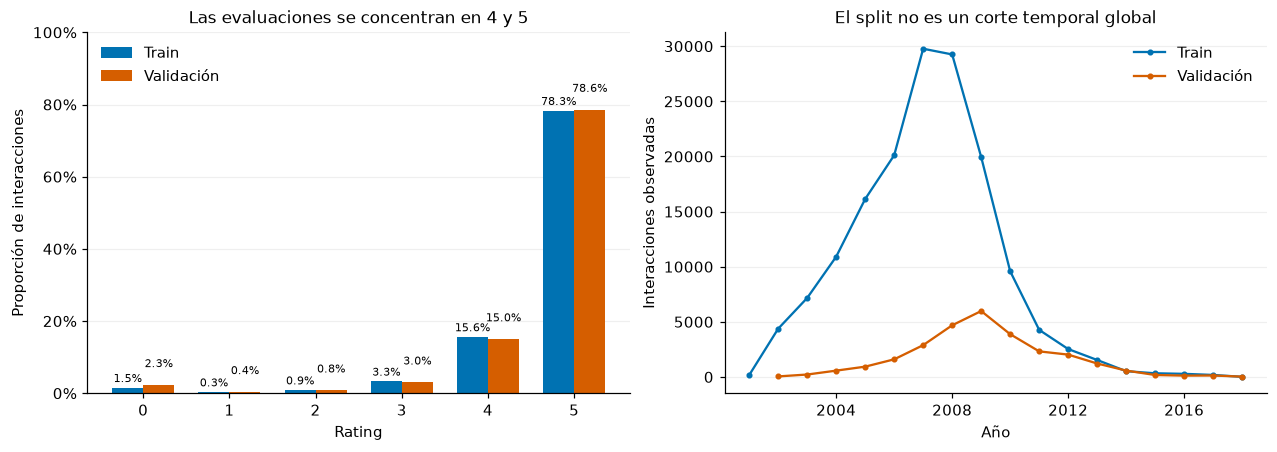

In [4]:
fig = plot_ratings_time(df, validation)
plt.show()


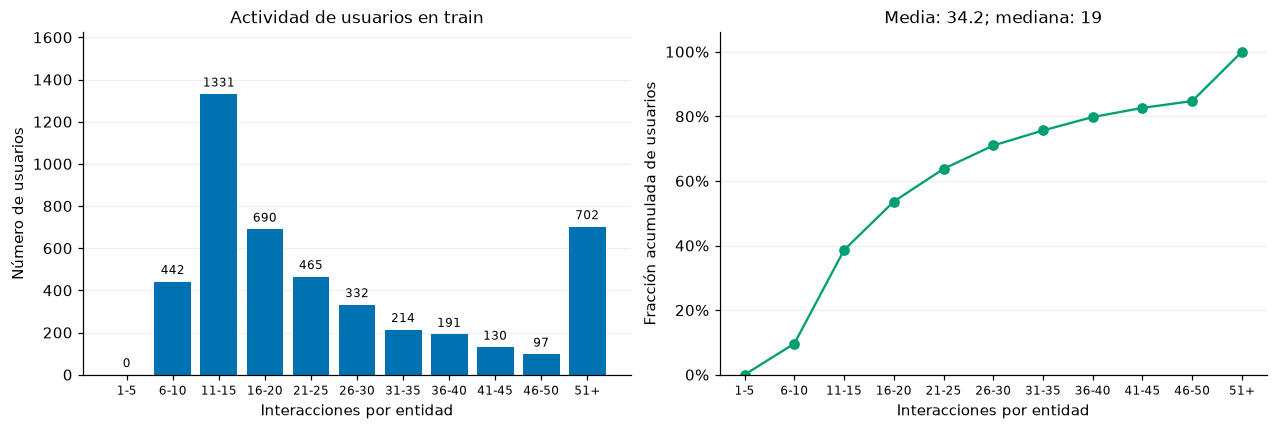

In [5]:
user_counts = df["user_id"].value_counts()
fig = plot_activity(user_counts, "usuarios")
plt.show()


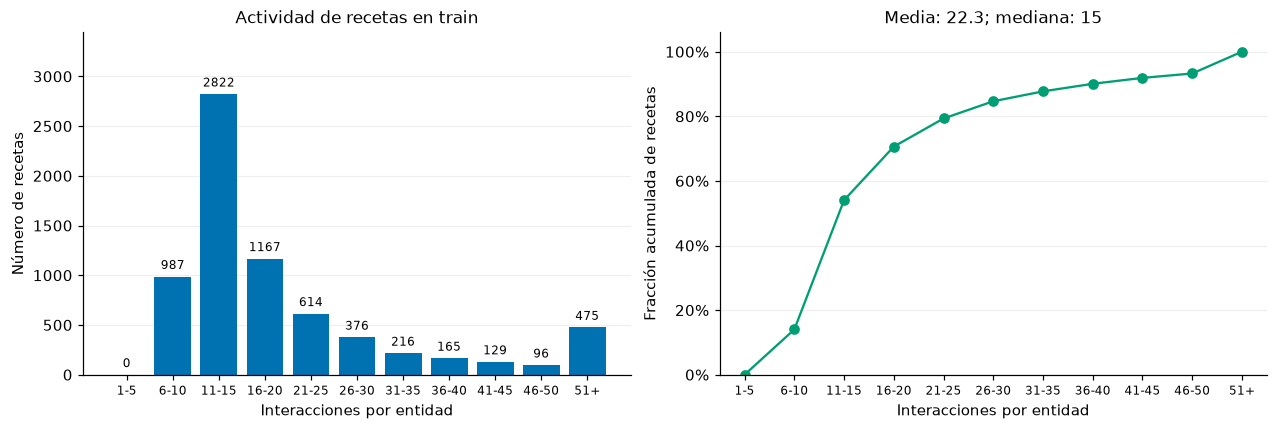

,users,recipes
mean,34.198520,22.294310
median,19.000000,15.000000
min,10.000000,10.000000
max,1082.000000,524.000000
at_most_5_fraction,0.000000,0.000000
at_most_10_fraction,0.096212,0.140060
top_1pct_interaction_fraction,0.104062,0.086819
top_10pct_interaction_fraction,0.412188,0.339403


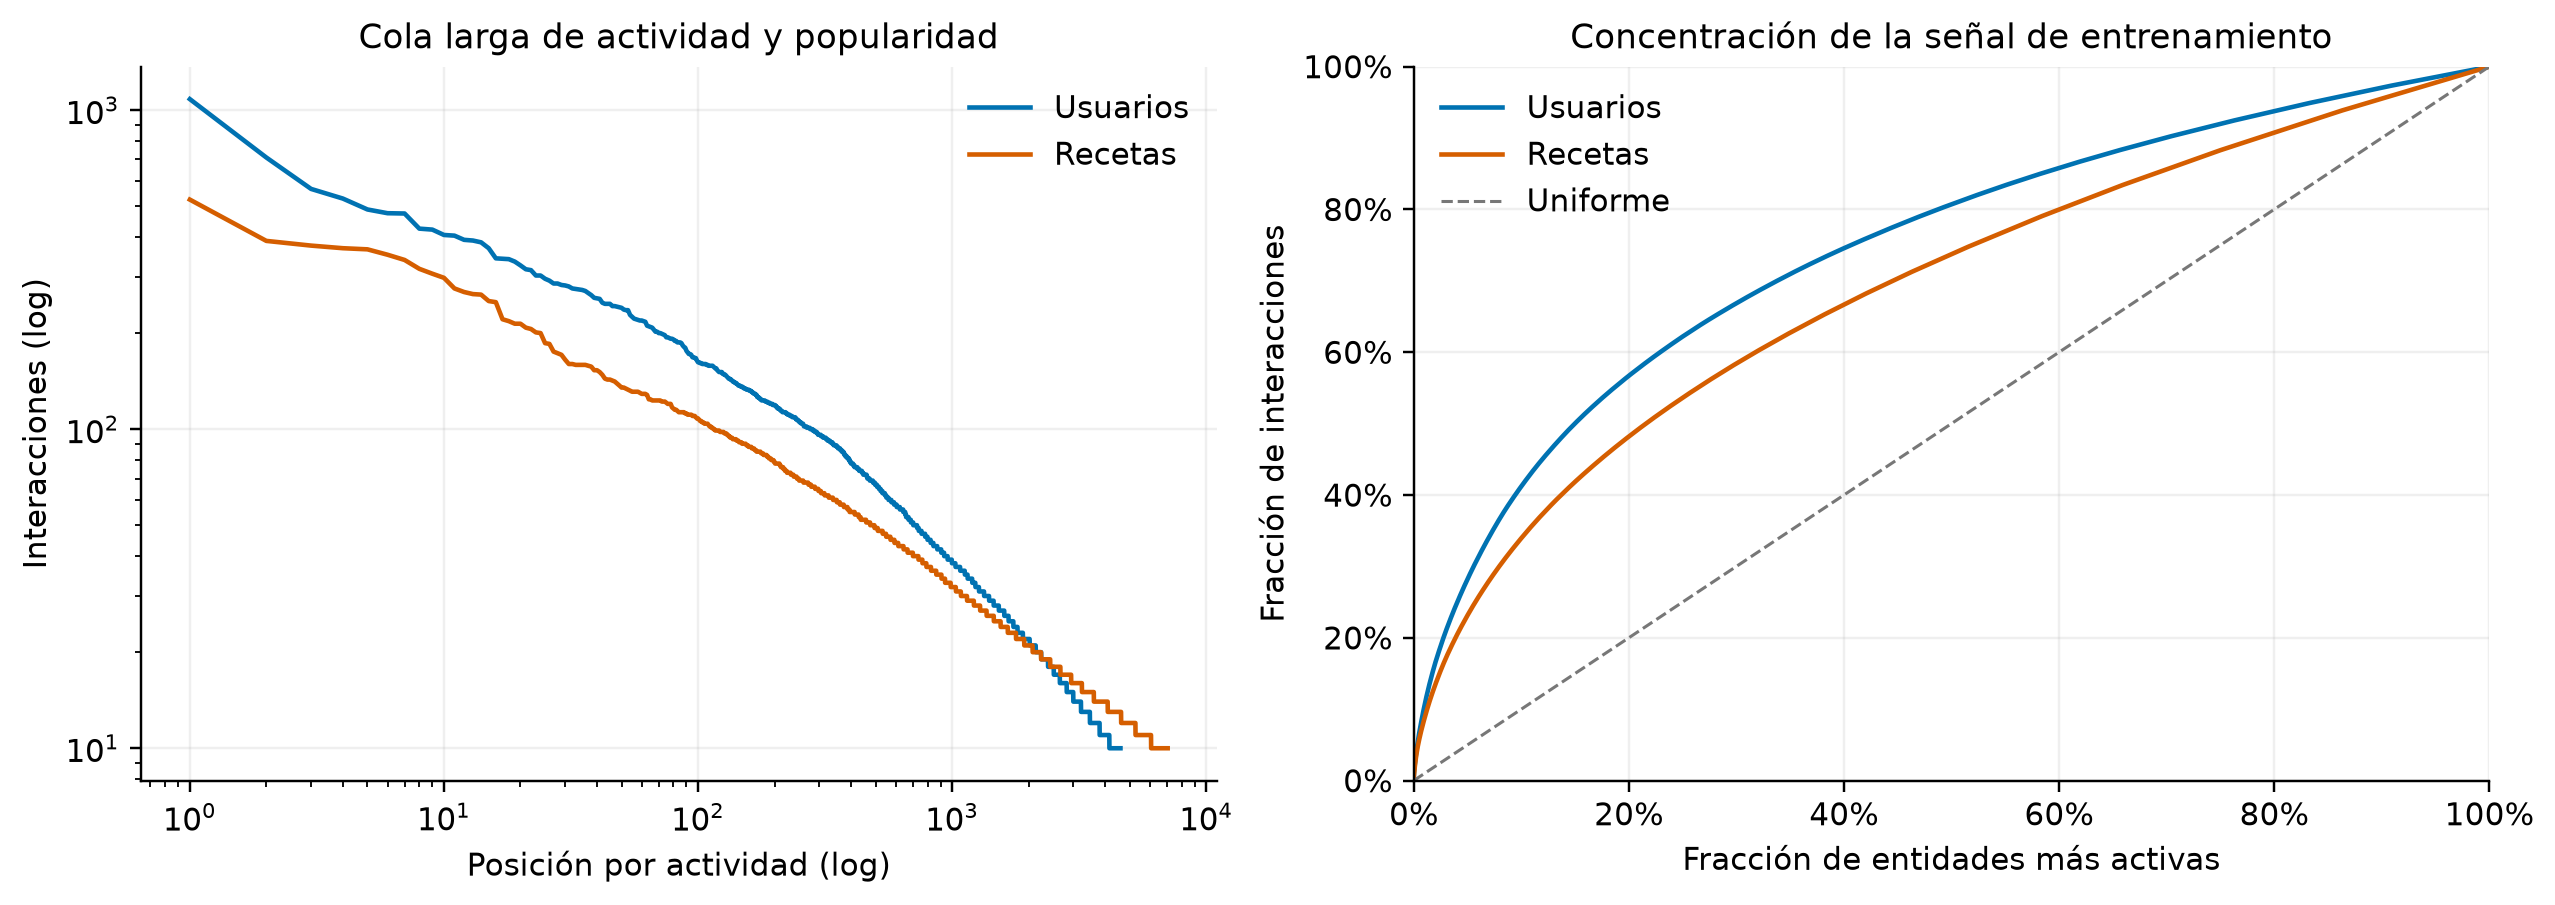

In [6]:
recipe_counts = df["recipe_id"].value_counts()
fig = plot_activity(recipe_counts, "recetas")
plt.show()
display(pd.DataFrame(summary["activity"]))
display(Image(filename=str(assets_path / "eda_long_tail.png")))


In [7]:
top_k = 5
metadata = pd.read_csv(dataset_path / 'item_metadata.csv')

## Recetas más populares

Ordenamos por número de interacciones y mostramos también el rating medio. El soporte permite distinguir popularidad de calidad percibida.


In [8]:
top_recipes(df, metadata, top_k=top_k, by="popularity")


,recipe_id,mean_rating,n_ratings,name
0,27208,4.484733,524,to die for crock pot roast
1,22782,4.650386,389,jo mama s world famous spaghetti
2,89204,4.380319,376,crock pot chicken with black beans cream cheese
3,32204,4.661247,369,whatever floats your boat brownies
4,39087,4.726776,366,creamy cajun chicken pasta


## Recetas mejor evaluadas

El ranking se ordena por rating medio descendente, número de evaluaciones descendente e ID ascendente para desempatar. Exigimos al menos 10 evaluaciones para no interpretar una sola nota máxima como evidencia sólida; este umbral es descriptivo, no un filtro del dataset de entrenamiento.


In [9]:
top_recipes(df, metadata, top_k=top_k, min_ratings=10)


,recipe_id,mean_rating,n_ratings,name
0,87689,5.0,43,cake flour substitute
1,66947,5.0,41,refreshing mojito by the pitcher mojitos
2,77497,5.0,41,2 handed kitchen sink tomato sandwich
3,51550,5.0,35,real southern cornbread
4,61816,5.0,33,rosemary garlic focaccia


## Hallazgos y vínculo con los modelos

Las tablas anteriores distinguen densidad sobre el universo propio de cada split y sobre el universo fijo de train: comparar densidades con denominadores distintos puede inducir una conclusión errónea. Los archivos de auditoría incluyen nulos, duplicados, pares compartidos y usuarios/recetas ausentes en train.

La concentración en ratings altos justifica contrastar RMSE/MAE contra baselines simples, y tratar ranking como un objetivo separado. Un cero observado y un candidato no observado no tienen el mismo origen: los segundos solo se usan como negativos de evaluación del ranking.

La cola larga y la diferencia media-mediana motivan comparar vecindarios locales (ItemKNN) con factores compartidos (FunkSVD). La presencia de al menos diez interacciones por entidad indica que esta muestra está filtrada: sus resultados no demuestran comportamiento de cold-start real.

La auditoría temporal comprueba el orden por usuario a resolución de día. Los usuarios con frontera en el mismo día no permiten demostrar un orden intradiario estricto. El solapamiento entre años de train y validación muestra que no hay un único corte temporal global.

Las figuras PNG/PDF y las tablas CSV/JSON se regeneran en `../informe_assets/`; `data/eda_summary.json` registra hashes SHA-256 de las tres fuentes.
